In [1]:
import at3d
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc

In [2]:
def load_measurements(file_name):
    """
    Load from netCDF the sensors that were saved using 'save_forward_model'
    above. Adapted from at3d.util.load_forward_model.
    """
    dataset = nc.Dataset(file_name)

    groups = dataset.groups
    sensors = groups['sensors'].groups
    sensor_dict = at3d.containers.SensorsDict()

    for key, sensor in sensors.items():
        sensor_list = []
        for i, image in sensor.groups.items():
            sensor_dataset = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset[
                'sensors/{}/{}'.format(key, i)]))
            sensor_dataset['stokes'] = (['stokes_index'],sensor_dataset['stokes'].data.astype(bool))
            sensor_dataset['use_subpixel_rays'] = sensor_dataset['use_subpixel_rays'].data.astype(bool)
            sensor_dict.add_sensor(key, sensor_dataset)
    return sensor_dict

In [3]:
def plot_measurements(sensor_dict, instrument, fig, ax, s=2):
    sensor_list = sensor_dict[instrument]['sensor_list']
    for i, cam in enumerate(sensor_list):
        z = np.unique(cam.ray_z.data)
        if(len(z) == 1):
            title = '{}\nz={} km'.format(cam.name, z[0])
        else:
            title = '{}\nz=non-uniform'.format(cam.name)
        ax[i].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray')
        ax[i].set_title(title)

def plot_mask(sensor_dict, instrument, fig, ax, s=2):
    sensor_list = sensor_dict[instrument]['sensor_list']
    for i, cam in enumerate(sensor_list):
        z = np.unique(cam.ray_z.data)
        if(len(z) == 1):
            title = '{}\nz={} km'.format(cam.name, z[0])
        else:
            title = '{}\nz=non-uniform'.format(cam.name)
        ax[i].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.cloud_mask.data, vmin=0, vmax=1, marker='s', cmap='gray')
        ax[i].set_title(title)

In [4]:
expr_dir = '../../../dev/'
rte_grid = xr.load_dataset('{}rte_grid.nc'.format(expr_dir))
measurements = load_measurements('{}measurements.nc'.format(expr_dir))

In [5]:
# # TODO: I'll have to get the manual cloud mask from SALT, pass it into the preprocess2 script (or something similar), and save it as a new mask file
# nadir_mask_file = '/Users/johntl3/Documents/SALT/labels/test_cloud_mask_AN_labels.hdf'
# ncf = nc.Dataset(nadir_mask_file, diskless=True, persist=False)
# mask = ncf['Manual Labels'][:].data

In [6]:
# f, ax = plt.subplots(1, 1, figsize=(8,6))
# ax.imshow(mask, cmap='gray_r')

In [7]:
masked_sensors = at3d.containers.SensorsDict()
# thresholds = [0.120, 0.076, 0.054, 0.044, 0.040, 0.045, 0.052, 0.068, 0.092] # Developed later
thresholds = [0.133, 0.097, 0.072, 0.064, 0.061, 0.068, 0.075, 0.090, 0.111] # MS
for i, sensor in enumerate(measurements['MISR']['sensor_list']):
    sensor_copy = sensor.copy(deep=True)
    mask = np.zeros(sensor.dims['nrays'])
    mask[sensor_copy.I.data*np.pi/sensor_copy.mu0 > thresholds[i]] = 1
    sensor_copy['cloud_mask'] = (['nrays'], mask)
    masked_sensors.add_sensor('MISR', sensor_copy)

In [8]:
space_carver = at3d.space_carve.SpaceCarver(rte_grid, bcflag=3)
carved_volume = space_carver.carve(masked_sensors, agreement=(0.0, 0/9), linear_mode=False)
carved_volume['rel_cloudy'] = carved_volume.cloudy_counts / carved_volume.total_counts
carved_volume.to_netcdf('{}carved_volume_MS.nc'.format(expr_dir))

In [9]:
# fig, ax = plt.subplots(2, 9, figsize=(17, 5), sharex=True, sharey=True)
# plot_measurements(measurements, 'MISR', fig, ax[0,:], s=2)
# plot_mask(masked_sensors, 'MISR', fig, ax[1,:], s=2)

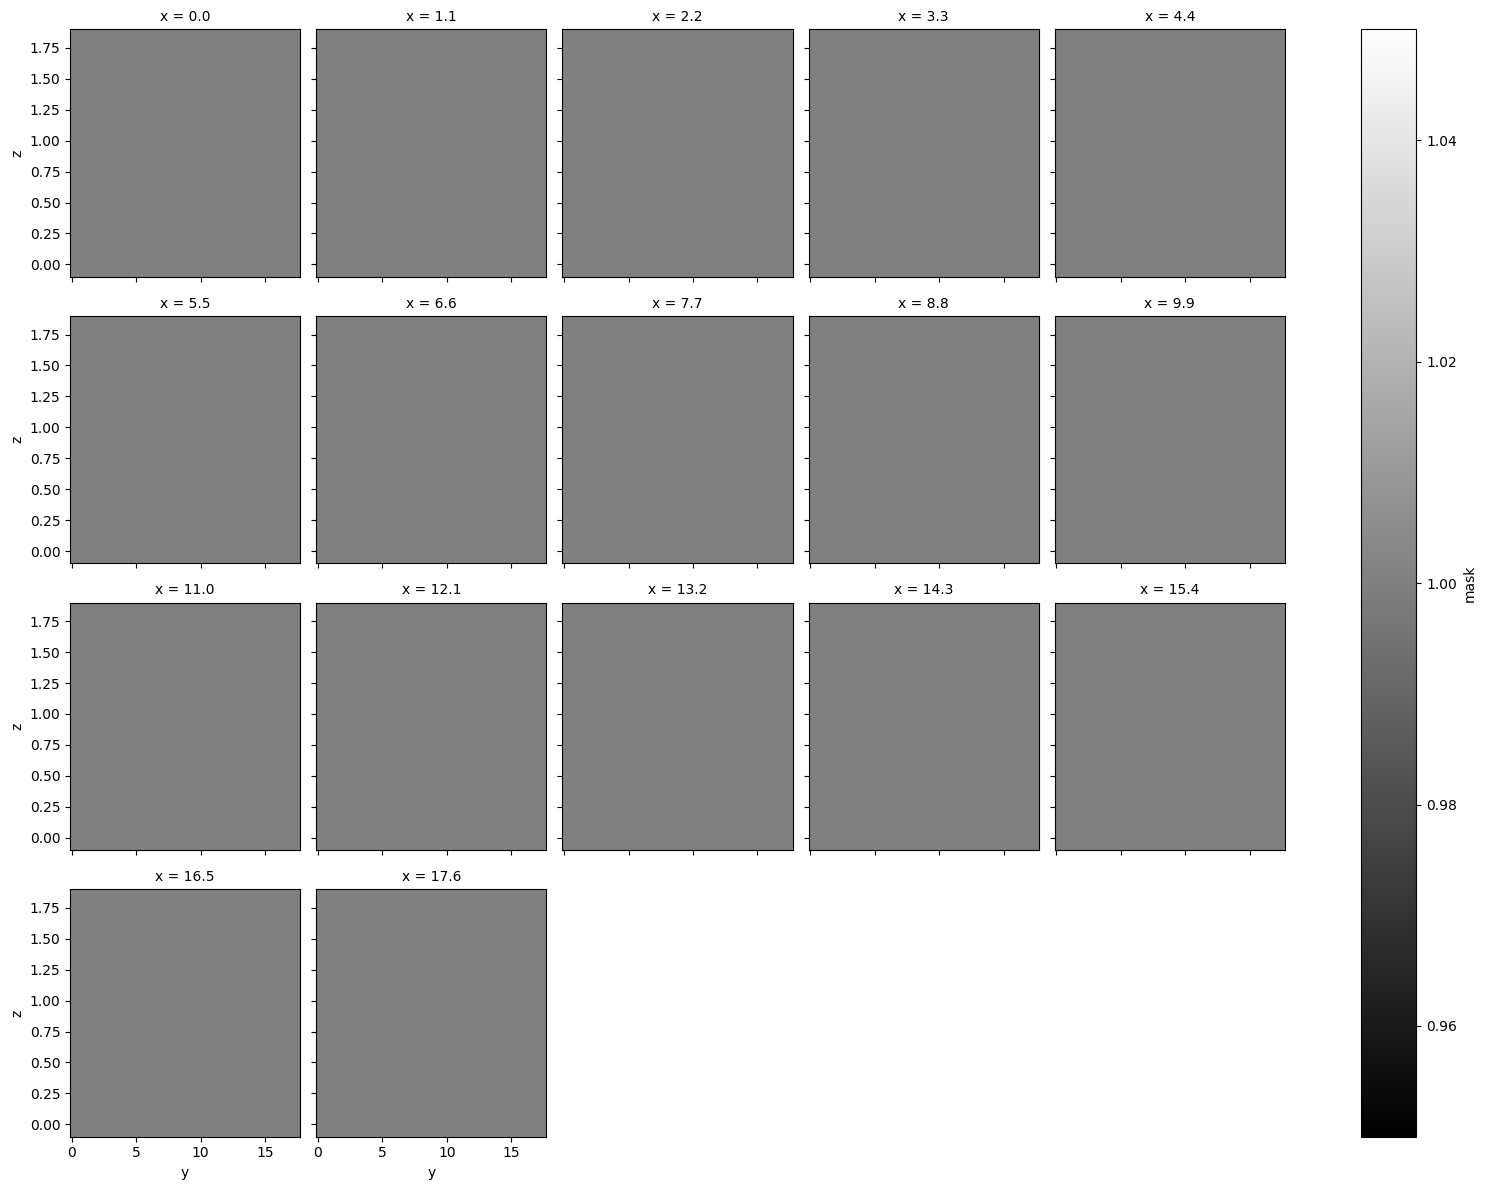

In [10]:
carved_volume.mask.isel(x=slice(0,None,4)).plot(x='y',y='z', col='x', col_wrap=5, cmap='gray')

In [9]:
carved_volume

<xarray.Dataset>
Dimensions:         (nsensors: 9, x: 65, y: 65, z: 17)
Coordinates:
  * x               (x) float64 0.0 0.275 0.55 0.825 ... 16.78 17.05 17.33 17.6
  * y               (y) float64 0.0 0.275 0.55 0.825 ... 16.78 17.05 17.33 17.6
  * z               (z) float64 0.0 0.2 0.39 0.4 0.5 ... 1.3 1.4 1.41 1.6 1.8
Dimensions without coordinates: nsensors
Data variables:
    cloudy_counts   (nsensors, x, y, z) int64 2033 3860 3382 ... 1912 1836 849
    total_counts    (nsensors, x, y, z) int64 3097 5958 5400 ... 3466 3376 1607
    weights         (nsensors, x, y, z) float64 3.097e+03 ... 1.607e+03
    mask            (x, y, z) int64 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1 1
    masked_weights  (x, y, z) float64 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    rel_cloudy      (nsensors, x, y, z) float64 0.6564 0.6479 ... 0.5438 0.5283